# Session 3: Normal Approximation of the Binomial

*ECE 225A, Module 04 (The Normal Distribution), deck 9.Normal_approximation_binomial_distribution, slides 1-17*

The binomial distribution is everywhere, but its probabilities are awkward: huge factorials for a single value, and long sums for an interval. The De Moivre-Laplace theorem says that near its mean, the binomial PMF is close to the normal density with the same mean and variance. That replaces one hard formula with an easy one, but three questions remain. A continuous variable gives any single value probability 0, so in what sense does a binomial probability equal a normal one? Must interval probabilities still be summed term by term? And can the Z table help? All three have one answer: the **continuity correction**, which reads a density at $k$ as the probability of the interval from $k - \frac{1}{2}$ to $k + \frac{1}{2}$.

## Learning objectives

After this session you should be able to:

1. State the De Moivre-Laplace theorem, including what $\simeq$ means and for which $k$ it holds.
2. Approximate $B_{p,n}(k)$ by $N_{np,npq}(k)$, and judge when the approximation is good.
3. Prove the theorem for $k = np$ with Stirling's approximation.
4. Explain why $P(X = k) \approx P(Y = k)$ is false, and why a density at $k$ nearly equals a probability over a unit interval.
5. Apply the continuity correction to single values and intervals, and use the Z table to find them.
6. Translate any event about a binomial, with strict or non-strict inequalities, into the correct normal event.

## Prerequisites

- The binomial distribution, with $\mu = np$, $V = npq$ (Module 01, Session 5).
- Stirling's approximation and the central binomial term (Module 02, Session 1).
- The normal density (Session 1).
- Z scores, $\Phi$, and the Z table (Session 2).

In [1]:
from math import comb, exp, factorial, pi, sqrt

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, norm

rng = np.random.default_rng(225)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, FAINT, GRID = "#0b0b0b", "#52514e", "#c3c2b7", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})

Phi = norm.cdf


def normal_density(x, mu, var):
    # The density N_{mu, var}(x), written out from the definition.
    return np.exp(-(x - mu) ** 2 / (2 * var)) / np.sqrt(2 * pi * var)


def normal_interval(a, b, mu, var):
    # P(a <= Y <= b) for Y ~ N_{mu, var}, by standardizing.
    sigma = sqrt(var)
    return Phi((b - mu) / sigma) - Phi((a - mu) / sigma)

## 1. Why approximate? (slides 1-2)

The binomial is significant but complicated. It can be approximated by a normal distribution, but which one? The natural choice is the normal with the **same mean and variance**:

$$B_{p,n} \text{ has } \mu = np \text{ and } V = npq, \quad \text{so use } N_{np,\,npq}.$$

Then, for all $k \approx np$,

$$B_{p,n}(k) \approx N_{np,npq}(k),$$

where the left side is a binomial probability, and the right side is the normal *density* evaluated at $k$.

**Example.** For $B_{1/4,\,48}$, we have $\mu = 48 \cdot \frac{1}{4} = 12$ and $V = 12 \cdot \frac{3}{4} = 9$, so use $N_{12,9}$.

(The slides write the subscripts in both orders, $B_{n,p}$ and $B_{p,n}$. We follow Module 01 and write $B_{p,n}$. So the $B_{48,1/4}$ on slide 2 is our $B_{1/4,\,48}$.)

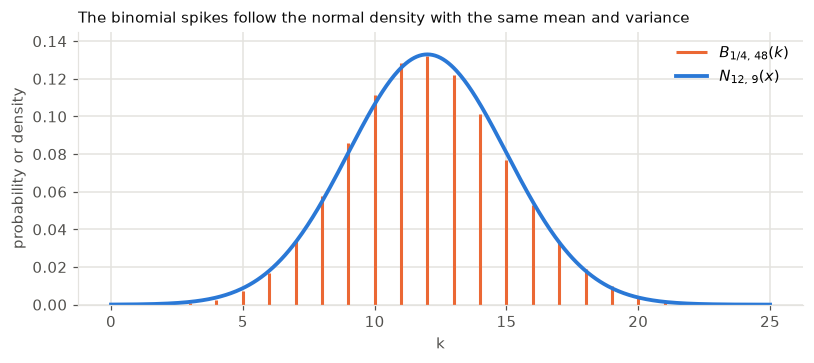

In [2]:
n, p = 48, 1 / 4
mu, var = n * p, n * p * (1 - p)
ks = np.arange(0, 26)
xs = np.linspace(0, 25, 501)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.vlines(ks, 0, binom.pmf(ks, n, p), color=ORANGE, lw=2, label=r"$B_{1/4,\,48}(k)$")
ax.plot(xs, normal_density(xs, mu, var), color=BLUE, lw=2.5, label=r"$N_{12,\,9}(x)$")
ax.set(xlabel="k", ylabel="probability or density", ylim=(0, 0.145))
ax.legend(frameon=False)
ax.set_title("The binomial spikes follow the normal density with the same mean and variance", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 2. The De Moivre-Laplace theorem (slide 3)

**Theorem.** Let $B_{p,n}$ have $\mu = np$, $V = npq$, and $\sigma = \sqrt{npq}$, with $q = 1 - p$. For every $p \in (0, 1)$ and every $c > 0$, as $n \to \infty$, for all $k$ with

$$\lvert k - np \rvert \le c\sqrt{npq},$$

that is, for $k$ within $c$ standard deviations of $\mu$,

$$B_{p,n}(k) \simeq N_{np,npq}(k).$$

Here $\simeq$ means that the ratio of the left and right sides tends to 1.

The next sections give an example, and prove the case $k = np$. A later generalization to sums of other independent variables is the Central Limit Theorem.

In [3]:
# Worst ratio B/N over all k within c standard deviations of the mean, as n grows.
p, q = 1 / 4, 3 / 4
print("    n     c = 1              c = 2              c = 3")
for n in [48, 480, 4_800, 48_000, 480_000]:
    mu, var = n * p, n * p * q
    cells = []
    for c in (1, 2, 3):
        lo, hi = int(np.ceil(mu - c * sqrt(var))), int(np.floor(mu + c * sqrt(var)))
        k = np.arange(lo, hi + 1)
        ratio = binom.pmf(k, n, p) / normal_density(k, mu, var)
        cells.append(f"[{ratio.min():.4f}, {ratio.max():.4f}]")
    print(f"{n:7,}  " + "   ".join(cells))

    n     c = 1              c = 2              c = 3
     48  [0.9511, 1.0636]   [0.9417, 1.0636]   [0.4366, 1.4538]
    480  [0.9831, 1.0182]   [0.9831, 1.0183]   [0.8462, 1.1430]
  4,800  [0.9945, 1.0056]   [0.9944, 1.0056]   [0.9494, 1.0495]
 48,000  [0.9983, 1.0018]   [0.9983, 1.0018]   [0.9843, 1.0156]
480,000  [0.9994, 1.0006]   [0.9994, 1.0006]   [0.9950, 1.0050]


## 3. The approximation in action, take 1 (slide 4)

**Problem.** Find $B_{0.5,\,100}(60)$.

**Exact.**

$$B_{0.5,\,100}(60) = \binom{100}{60}\, 0.5^{60} \cdot (1 - 0.5)^{40} \approx 0.010844.$$

**Normal approximation.** Use the same mean and variance, $\mu = 100 \cdot 0.5 = 50$ and $\sigma^2 = 100 \cdot 0.5 \cdot 0.5 = 25$. The exponent is $-\frac{(60 - 50)^2}{2 \cdot 25} = -2$, so

$$B_{0.5,\,100}(60) \simeq N_{50,25}(60) = \frac{1}{\sqrt{2\pi \cdot 25}}\, e^{-2} \approx 0.010798,$$

which is only 0.4% below the exact value. The approximation improves as $npq \to \infty$ and as $k \to np$.

In [4]:
exact = comb(100, 60) * 0.5 ** 100
approx = normal_density(60, 50, 25)
print(f"exact  {exact:.6f}")
print(f"normal {approx:.6f}")
print(f"relative error {(approx - exact) / exact:+.2%}\n")

print("The approximation improves as npq grows, and as k approaches np:")
print("     n    p    k    exact        normal       relative error")
for n, p, k in [(20, 0.5, 14), (100, 0.5, 60), (100, 0.5, 70), (1_000, 0.5, 530), (1_000, 0.5, 500), (100, 0.1, 18), (10_000, 0.1, 1_040)]:
    mu, var = n * p, n * p * (1 - p)
    b, m = binom.pmf(k, n, p), normal_density(k, mu, var)
    print(f"{n:6} {p:4} {k:5}  {b:.4e}   {m:.4e}   {(m - b) / b:+.2%}")

exact  0.010844
normal 0.010798
relative error -0.42%

The approximation improves as npq grows, and as k approaches np:
     n    p    k    exact        normal       relative error
    20  0.5    14  3.6964e-02   3.6021e-02   -2.55%
   100  0.5    60  1.0844e-02   1.0798e-02   -0.42%
   100  0.5    70  2.3171e-05   2.6766e-05   +15.52%
  1000  0.5   530  4.1727e-03   4.1707e-03   -0.05%
  1000  0.5   500  2.5225e-02   2.5231e-02   +0.03%
   100  0.1    18  5.4265e-03   3.7987e-03   -30.00%
 10000  0.1  1040  5.4281e-03   5.4670e-03   +0.72%


## 4. Proof for $k = np$ (slide 5)

**Claim.** For all $p$, as $n \to \infty$, $B_{p,n}(k) \simeq N_{pn,pqn}(k)$ at $k = pn$. (Assume that $pn$ is an integer.)

**The binomial side.** With $q = 1 - p$,

$$B_{p,n}(pn) = \binom{n}{pn} p^{pn} q^{qn} = \frac{n!}{(pn)!\, (qn)!}\, p^{pn} q^{qn}.$$

Apply **Stirling's approximation**, $n! \simeq \sqrt{2\pi n}\, (n/e)^n$, to all three factorials, which is valid as $n \to \infty$:

$$\simeq \frac{\sqrt{2\pi n}\, (n/e)^n}{\sqrt{2\pi pn}\, (pn/e)^{pn} \cdot \sqrt{2\pi qn}\, (qn/e)^{qn}} \cdot p^{pn} q^{qn}.$$

Now cancel, using $pn + qn = n$:

- Powers of $n/e$: $(n/e)^n$ on top cancels $(n/e)^{pn}(n/e)^{qn}$ on the bottom.
- Powers of $p$ and $q$: $p^{pn} q^{qn}$ on the bottom cancels the same factor on the right.
- Square roots: $\frac{\sqrt{2\pi n}}{\sqrt{2\pi pn}\, \sqrt{2\pi qn}} = \frac{1}{\sqrt{2\pi \cdot pqn}}$.

So $B_{p,n}(pn) \simeq \frac{1}{\sqrt{2\pi \cdot pqn}}$.

**The normal side.** At its own mean the exponent vanishes:

$$N_{pn,pqn}(pn) = \frac{1}{\sqrt{2\pi \cdot pqn}}\, e^{-\frac{(pn - pn)^2}{2 \cdot pqn}} = \frac{1}{\sqrt{2\pi \cdot pqn}}.$$

The two sides agree. $\checkmark$

**A link to Module 02.** With $p = \frac{1}{2}$ and $2n$ trials, this says $\frac{1}{\sqrt{2\pi \cdot \frac{1}{4} \cdot 2n}} = \frac{1}{\sqrt{\pi n}}$, the central binomial rate from the "Why Vote" session. The peak is about $0.4/\sigma$, which is the "peak is about $1/\sigma$" rule made exact.

In [5]:
print("    n    p    B(np)          1/sqrt(2 pi npq)    ratio")
for n, p in [(10, 0.5), (100, 0.5), (10_000, 0.5), (100, 0.2), (10_000, 0.2), (100, 0.7), (10_000, 0.7)]:
    k = round(n * p)
    b = binom.pmf(k, n, p)
    m = 1 / sqrt(2 * pi * n * p * (1 - p))
    print(f"{n:6} {p:4}   {b:.6f}       {m:.6f}          {b / m:.6f}")

print("\nStirling for 20!:")
print(f"  exact {factorial(20):.5e}, Stirling {sqrt(2 * pi * 20) * (20 / np.e) ** 20:.5e}")

    n    p    B(np)          1/sqrt(2 pi npq)    ratio
    10  0.5   0.246094       0.252313          0.975350
   100  0.5   0.079589       0.079788          0.997503
 10000  0.5   0.007979       0.007979          0.999975
   100  0.2   0.099300       0.099736          0.995635
 10000  0.2   0.009973       0.009974          0.999956
   100  0.7   0.086784       0.087056          0.996870
 10000  0.7   0.008705       0.008706          0.999969

Stirling for 20!:
  exact 2.43290e+18, Stirling 2.42279e+18


## 5. Three questions (slides 6-9)

The approximation is useful, but it leaves three questions open.

**Quiz 1.** Suppose $X \sim B_{p,n}$ and $Y \sim N_{pn,pqn}$, with $p$, $n$, $k$ as above. Then is $P(X = k) \approx P(Y = k)$? **No!**

$$P(X = k) = \binom{n}{k} p^k q^{n-k} \approx \frac{1}{\sqrt{2\pi \cdot npq}}\, e^{-\frac{(k - \mu)^2}{2npq}} > 0, \qquad \text{but} \qquad P(Y = k) = 0,$$

since $Y$ is continuous. A binomial **probability** approximates a normal **density**, not a normal probability. Can a probability be made to appear instead?

**Quiz 2.** We approximated a binomial probability of one value, $P(X = k)$. What about an interval, $P(k_1 \le X \le k_2)$? We can sum, $\sum_{k = k_1}^{k_2} P(X = k)$, and approximate each term. Can we do better?

**Quiz 3.** We worked hard to derive and understand the Z table. Can we use it here?

The next topic answers all three.

## 6. Function $\approx$ integral (slide 10)

Let $f : \mathbb{R} \to \mathbb{R}$ be continuous, and consider the unit interval centered at $k$.

**If $f$ is linear** there, with endpoint values $a$ and $b$, then its value at the midpoint is the average, and this equals the area of a trapezoid of width 1:

$$f(k) = \frac{a + b}{2} \cdot 1 = \text{Area} = \int_{k - 1/2}^{k + 1/2} f(x)\, dx.$$

**If $f$ is approximately linear**, then the equalities become approximations.

**For a normal density with large $\sigma$**, the curve is approximately linear over any interval of unit length, so

$$N_{\mu,\sigma^2}(k) \approx \int_{k - 1/2}^{k + 1/2} N_{\mu,\sigma^2}(x)\, dx = P\left[k - \frac{1}{2},\, k + \frac{1}{2}\right].$$

This is consistent with what a density means: $P[k - \frac{\delta}{2}, k + \frac{\delta}{2}] \approx \delta f(k)$ as $\delta \to 0$. (The slide prints $2\delta f(k)$, a typo, since the interval has length $\delta$.) Near-linearity means that we need no limit here: $\delta = 1$ is already small enough.

In [6]:
mu, var = 50, 25
print("Large sigma, N(50, 25):")
print("  k    density at k   P[k - 1/2, k + 1/2]   relative difference")
for k in [50, 53, 55, 60, 65, 70]:
    d, i = normal_density(k, mu, var), normal_interval(k - 0.5, k + 0.5, mu, var)
    print(f"{k:3}    {d:.6f}       {i:.6f}             {(i - d) / d:+.3%}")

print("\nSmall sigma, N(0, 0.09), where a unit interval is not short compared to sigma:")
d, i = normal_density(0, 0, 0.09), normal_interval(-0.5, 0.5, 0, 0.09)
print(f"density at 0 = {d:.4f}, P[-1/2, 1/2] = {i:.4f}")

Large sigma, N(50, 25):
  k    density at k   P[k - 1/2, k + 1/2]   relative difference
 50    0.079788       0.079656             -0.166%
 53    0.066645       0.066574             -0.107%
 55    0.048394       0.048394             -0.000%
 60    0.010798       0.010852             +0.500%
 65    0.000886       0.000898             +1.336%
 70    0.000027       0.000027             +2.514%

Small sigma, N(0, 0.09), where a unit interval is not short compared to sigma:
density at 0 = 1.3298, P[-1/2, 1/2] = 0.9044


## 7. Approximation via normal probabilities (slide 11)

Combining the theorem with Section 6, for $X \sim N_{np,npq}$,

$$B_{p,n}(k) \simeq N_{np,npq}(k) \approx \int_{k - 1/2}^{k + 1/2} N_{np,npq}(x)\, dx = P\left(k - \frac{1}{2} \le X \le k + \frac{1}{2}\right).$$

This use of the interval from $k - \frac{1}{2}$ to $k + \frac{1}{2}$ is the **continuity correction**. Standardizing with $Z = \frac{X - \mu}{\sigma}$ gives

$$= P\left(\frac{k - np - 1/2}{\sqrt{npq}} \le Z \le \frac{k - np + 1/2}{\sqrt{npq}}\right).$$

So a binomial probability approximates a normal density, and that density in turn approximates a normal **probability**. This answers Quiz 1, and it opens the door to the Z table, answering Quiz 3.

## 8. The approximation in action, take 2 (slide 12)

For $B_{0.5,\,100}(60)$, with $Y \sim N_{50,25}$ and $Z = \frac{Y - 50}{5}$, there are now three ways:

1. **Exact:** $\binom{100}{60}\, 0.5^{60} (1 - 0.5)^{40} \approx 0.010844$.
2. **Density:** $N_{50,25}(60) = \frac{1}{\sqrt{2\pi \cdot 25}}\, e^{-2} \approx 0.010798$.
3. **Probability:** $P(59.5 \le Y \le 60.5) = P\big(\frac{59.5 - 50}{5} \le Z \le \frac{60.5 - 50}{5}\big) = P(1.9 \le Z \le 2.1)$, which gives

$$\Phi(2.1) - \Phi(1.9) \approx 0.9821 - 0.9713 = 0.0108.$$

**Did $Z$ buy us anything?** Not yet, for a single value. The density formula was already easy, and the table has only four digits. But the best is yet to come.

In [7]:
print(f"1. exact:              {binom.pmf(60, 100, 0.5):.6f}")
print(f"2. density:            {normal_density(60, 50, 25):.6f}")
print(f"3. interval, program:  {normal_interval(59.5, 60.5, 50, 25):.6f}")
print(f"3. interval, table:    {0.9821 - 0.9713:.4f}")

1. exact:              0.010844
2. density:            0.010798
3. interval, program:  0.010852
3. interval, table:    0.0108


## 9. Event probabilities (slide 13)

As usual, the probability of an event is the sum of its values' probabilities. For a segment of consecutive values,

$$P[k, k + 1, \dots, \ell] = \sum_{i = k}^{\ell} B_{p,n}(i) \approx \sum_{i = k}^{\ell} N_{pn,npq}(i).$$

This is easier for each term, but it is still a sum. Can we avoid the sum too? That would be a second gain on top of the first.

The picture suggests how. Each binomial probability is the area of a bar of width 1, centered at an integer, and the bars of a segment fit together side by side under the curve.

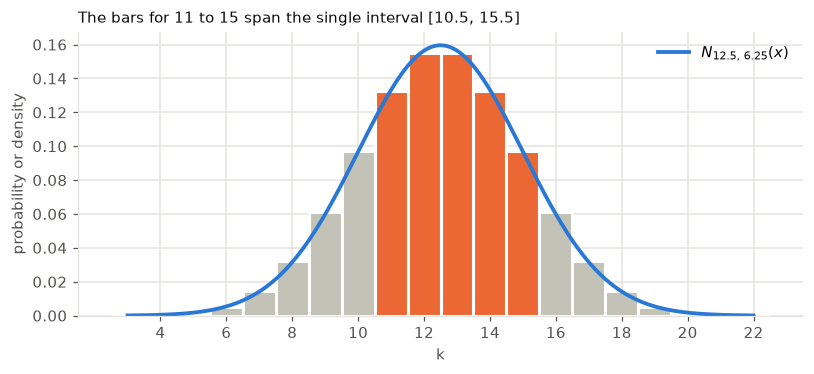

P(11 <= X <= 15): exact 0.6731, sum of densities 0.6762, single interval 0.6731


In [8]:
n, p = 25, 0.5
mu, var = n * p, n * p * (1 - p)
ks = np.arange(3, 23)
k1, k2 = 11, 15
xs = np.linspace(3, 22, 500)

fig, ax = plt.subplots(figsize=(7.5, 3.5))
colors = [ORANGE if k1 <= k <= k2 else FAINT for k in ks]
ax.bar(ks, binom.pmf(ks, n, p), width=1, color=colors, edgecolor="white", linewidth=2)
ax.plot(xs, normal_density(xs, mu, var), color=BLUE, lw=2.5, label=rf"$N_{{{mu:g},\,{var:g}}}(x)$")
ax.set(xlabel="k", ylabel="probability or density", xticks=range(4, 23, 2))
ax.legend(frameon=False)
ax.set_title(f"The bars for {k1} to {k2} span the single interval [{k1 - 0.5}, {k2 + 0.5}]", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

exact = binom.cdf(k2, n, p) - binom.cdf(k1 - 1, n, p)
print(f"P({k1} <= X <= {k2}): exact {exact:.4f}, sum of densities {normal_density(np.arange(k1, k2 + 1), mu, var).sum():.4f}, single interval {normal_interval(k1 - 0.5, k2 + 0.5, mu, var):.4f}")

## 10. Intervals (slide 14)

Let $X \sim B_{p,n}$ and $Y \sim N_{np,npq}$. For one value, as above, $P(X = 3) \approx P(2.5 \le Y \le 3.5)$. For two adjacent values,

$$P(3 \le X \le 4) = P(X = 3) + P(X = 4) \approx P(2.5 \le Y \le 3.5) + P(3.5 \le Y \le 4.5) = P(2.5 \le Y \le 4.5).$$

The unit intervals join, and only the two outer limits remain. In general,

$$\boxed{P(k \le X \le \ell) \approx P\left(k - \frac{1}{2} \le Y \le \ell + \frac{1}{2}\right).}$$

The sum has vanished, leaving a single difference of two table entries. This answers Quiz 2.

## 11. Example: an interval probability (slide 15)

**Problem.** Let $X \sim B_{0.5,\,100}$, so $np = 50$ and $\sqrt{npq} = 5$, and let $Y \sim N(50, 25)$. Approximate $P(42 \le X \le 53)$.

**Solution.**

$$P(42 \le X \le 53) \approx P(41.5 \le Y \le 53.5) = P\left(\frac{41.5 - 50}{5} \le Z \le \frac{53.5 - 50}{5}\right) = P(-1.7 \le Z \le 0.7).$$

With $\Phi(-a) = 1 - \Phi(a)$,

$$= \Phi(0.7) + \Phi(1.7) - 1 \approx 0.7580 + 0.9554 - 1 = 0.7134.$$

The exact value takes a sum of 12 large terms:

$$\sum_{k = 42}^{53} \binom{100}{k} \left(\frac{1}{2}\right)^{100} \approx 0.7136.$$

Two table lookups give an error of just 0.0002. This also answers Quiz 3: the Z table pays off for intervals. The correction matters too, as the cell below shows.

In [9]:
exact = sum(comb(100, k) for k in range(42, 54)) / 2 ** 100
print(f"exact sum:                   {exact:.4f}")
print(f"with continuity correction:  {normal_interval(41.5, 53.5, 50, 25):.4f}")
print(f"from the table:              {0.7580 + 0.9554 - 1:.4f}")
print(f"without the correction:      {normal_interval(42, 53, 50, 25):.4f}")

X = rng.binomial(100, 0.5, size=4_000_000)
print(f"simulated:                   {np.mean((X >= 42) & (X <= 53)):.4f}")

exact sum:                   0.7136
with continuity correction:  0.7135
from the table:              0.7134
without the correction:      0.6709


simulated:                   0.7134


## 12. Quiz: continuity correction (slide 16)

**Setup.** $X \sim B_{1/3,\,90}$ is approximated by $Y \sim N_{30,20}$, since $np = 30$ and $npq = 90 \cdot \frac{1}{3} \cdot \frac{2}{3} = 20$. Translate each event about $X$ into an event about $Y$.

**Method.** Since $X$ takes integer values, first list the integers in the event. Then extend half a unit beyond the smallest and the largest of them.

| $X$ event | Integers | $Y$ event | Note |
|---|---|---|---|
| $X = 20$ | $20$ | $19.5 < Y < 20.5$ | |
| $X \in \lbrace 17, 18 \rbrace$ | $17, 18$ | $16.5 < Y < 18.5$ | |
| $X \ge 24$ | $24, \dots, 90$ | $23.5 < Y < 90.5$ | $P(Y > 90.5)$ is tiny, so roughly $P(Y > 23.5)$ |
| $X > 26$ | $27, 28, \dots$ | $Y > 26.5$ | $X > 26$ iff $X \ge 27$ |
| $X < 15$ | $\dots, 13, 14$ | $Y < 14.5$ | $X < 15$ iff $X \le 14$ |
| $11 < X \le 13$ | $12, 13$ | $11.5 < Y < 13.5$ | |
| $19 < X < 21$ | $20$ | $19.5 < Y < 20.5$ | The same event as $X = 20$ |

In [10]:
n, p = 90, 1 / 3
mu, var = n * p, n * p * (1 - p)
sigma = sqrt(var)
print(f"mu = {mu:g}, var = {var:g}, sigma = {sigma:.3f}\n")

rows = [
    ("X = 20", 20, 20), ("X in {17, 18}", 17, 18), ("X >= 24", 24, 90),
    ("X > 26", 27, 90), ("X < 15", 0, 14), ("11 < X <= 13", 12, 13), ("19 < X < 21", 20, 20),
]
print(f"{'event':15} {'Y interval':18} {'exact':>9} {'normal':>9}")
for name, lo, hi in rows:
    exact = binom.cdf(hi, n, p) - binom.cdf(lo - 1, n, p)
    approx = normal_interval(lo - 0.5, hi + 0.5, mu, var)
    print(f"{name:15} ({lo - 0.5:>5}, {hi + 0.5:>5})    {exact:9.5f} {approx:9.5f}")

mu = 30, var = 20, sigma = 4.472

event           Y interval             exact    normal
X = 20          ( 19.5,  20.5)      0.00690   0.00738
X in {17, 18}   ( 16.5,  18.5)      0.00306   0.00379
X >= 24         ( 23.5,  90.5)      0.92921   0.92695
X > 26          ( 26.5,  90.5)      0.78157   0.78308
X < 15          ( -0.5,  14.5)      0.00012   0.00026
11 < X <= 13    ( 11.5,  13.5)      0.00004   0.00009
19 < X < 21     ( 19.5,  20.5)      0.00690   0.00738


## 13. Summary (slide 17)

| Topic | Result |
|---|---|
| De Moivre-Laplace theorem | $B_{p,n}(k) \simeq N_{np,npq}(k)$, a normal with the same $\mu$ and $\sigma$ |
| Individual values | $P(X = k) = B_{p,n}(k) \approx N_{np,npq}(k)$, the normal *density* at $k$ |
| Intervals, for $Y \sim N_{np,npq}$ | $P(k_1 \le X \le k_2) \approx P(k_1 - \frac{1}{2} \le Y \le k_2 + \frac{1}{2})$, the continuity correction |

## Common pitfalls

1. **Equating $P(X = k)$ with $P(Y = k)$.** The right side is 0. Use the density $N_{np,npq}(k)$, or the interval $P(k - \frac{1}{2} \le Y \le k + \frac{1}{2})$.
2. **Dropping the continuity correction.** In Section 11, omitting it gives $0.6709$ in place of $0.7134$, while the exact value is $0.7136$. Without it, $P(X \ge 60)$ and $P(X > 60)$ would also come out equal.
3. **Correcting in the wrong direction.** The interval must grow to include each integer's whole unit. $X \ge 24$ gives $Y > 23.5$, while $X > 24$ gives $Y > 24.5$. List the integers first.
4. **Using $npq$ as the standard deviation.** $N_{np,npq}$ names the variance. The Z score divides by $\sqrt{npq}$.
5. **Reading $\simeq$ as a statement about differences.** It says that the ratio tends to 1. The theorem also covers only $k$ within a fixed number of standard deviations of $np$, so far tails can have large relative errors.
6. **Using it when $npq$ is small.** For $B_{0.001,\,1000}$, we have $npq \approx 1$, and the distribution is skewed. The Poisson is the right tool there, and a common rule of thumb asks for $npq \ge 10$.
7. **Inventing an interval for an empty event.** $30 < X < 31$ contains no integers, so its probability is 0, not $P(30.5 < Y < 30.5)$ or similar.

## Key takeaways

- **Which normal:** the one with the same mean and variance, $N_{np,npq}$.
- **Theorem:** for fixed $p$ and $\lvert k - np \rvert \le c\sqrt{npq}$, $\;B_{p,n}(k)/N_{np,npq}(k) \to 1$.
- **Proof at $k = np$:** Stirling on the three factorials, and everything cancels to $\frac{1}{\sqrt{2\pi npq}}$, the normal's peak.
- **Density to probability:** a normal density with large $\sigma$ is nearly linear over a unit interval, so $N(k) \approx P(k - \frac{1}{2} \le Y \le k + \frac{1}{2})$.
- **Intervals:** $P(k \le X \le \ell) \approx P(k - \frac{1}{2} \le Y \le \ell + \frac{1}{2})$, so a long sum becomes two table lookups.
- **Example:** for $B_{0.5,\,100}$, $P(42 \le X \le 53) \approx 0.7134$, against the exact $0.7136$.
- **Translating events:** list the integers, and then extend half a unit beyond each end.
- Next: the course moves on to bivariate continuous distributions.